# Extension - repeated cross-validation and corrected paired comparisons

**Question.** Are the small differences between pipeline options and between models real, or just fold-to-fold noise?

**Brief and report.** Parts D and G. Report Sections 4.3 and 7. Training CV only.

The setup cell below makes the repository root the working folder, so `src/` can be imported, and defines two helpers: `results(name)` reads a table from `results/` and `show(...)` displays saved figures from `reports/figures/`.

In [1]:
import os, sys
from pathlib import Path
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import Image, Markdown, display
from src.common import ROOT
pd.set_option('display.precision', 3)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

def show(*names):
    """Display saved figures from reports/figures/."""
    for name in names:
        display(Markdown(f'**reports/figures/{name}**'))
        display(Image(filename=str(ROOT / 'reports' / 'figures' / name)))

def results(name):
    return pd.read_csv(ROOT / 'results' / name)

`repeated_uncertainty()` in `src/robustness.py` does three things:
1. Repeats the five-fold CV with a second seed, giving 2 × 5 folds.
2. Compares configurations on the same folds with the Nadeau–Bengio corrected interval.
3. Adjusts the p-values for many comparisons with Holm's method.

**How to read the output.** A difference counts only if its interval excludes 0 and its Holm-adjusted p-value is below 0.05.

D2-2 | repeated CV: ablation LR: reference: AP 0.628


D2-2 | repeated CV: ablation LR: no_scaling: AP 0.628


D2-2 | repeated CV: ablation LR: no_engineering: AP 0.611


D2-2 | repeated CV: ablation LR: feature_selection: AP 0.626


D2-2 | repeated CV: ablation LR: pca_95pct: AP 0.607


D2-2 | repeated CV: ablation LR: smote: AP 0.626


... (21 outputs left out)

D2-2 | repeated CV: tuned: Stacking: AP 0.693


,configuration,mean,sd,ci_low,ci_high,p_value,n,validation_train_ratio
0,ablation LR: reference,0.628,0.005,0.622,0.634,3.327e-18,10,0.25
1,ablation LR: no_scaling,0.628,0.005,0.621,0.634,3.077e-18,10,0.25
2,ablation LR: no_engineering,0.611,0.005,0.604,0.618,7.840e-18,10,0.25
3,ablation LR: feature_selection,0.626,0.005,0.620,0.632,2.699e-18,10,0.25
4,ablation LR: pca_95pct,0.607,0.006,0.599,0.615,4.189e-17,10,0.25
5,ablation LR: smote,0.626,0.005,0.619,0.633,5.262e-18,10,0.25
6,ablation LR: class_weight,0.625,0.005,0.619,0.632,4.671e-18,10,0.25
7,ablation LR: ordinal_encoding,0.559,0.007,0.550,0.568,2.408e-16,10,0.25
8,ablation LR: constant_numeric_imputation,0.628,0.005,0.622,0.634,3.331e-18,10,0.25
9,ablation LR: restore_duplicate_frequency,0.608,0.008,0.597,0.619,7.752e-16,10,0.25


,option,reference,mean,sd,ci_low,ci_high,p_value,n,validation_train_ratio,p_holm,family
0,ablation LR: no_scaling,ablation LR: reference,-2.344e-04,3.280e-04,-6.733e-04,2.046e-04,2.579e-01,10,0.25,5.157e-01,ablation LR
1,ablation LR: no_engineering,ablation LR: reference,-1.703e-02,1.994e-03,-1.970e-02,-1.436e-02,1.572e-07,10,0.25,1.258e-06,ablation LR
2,ablation LR: feature_selection,ablation LR: reference,-2.142e-03,1.134e-03,-3.659e-03,-6.247e-04,1.094e-02,10,0.25,4.376e-02,ablation LR
3,ablation LR: pca_95pct,ablation LR: reference,-2.062e-02,3.312e-03,-2.505e-02,-1.619e-02,2.336e-06,10,0.25,1.635e-05,ablation LR
4,ablation LR: smote,ablation LR: reference,-1.973e-03,1.442e-03,-3.903e-03,-4.336e-05,4.601e-02,10,0.25,1.380e-01,ablation LR
5,ablation LR: class_weight,ablation LR: reference,-2.676e-03,5.109e-04,-3.359e-03,-1.992e-03,9.769e-06,10,0.25,5.861e-05,ablation LR
6,ablation LR: ordinal_encoding,ablation LR: reference,-6.940e-02,4.943e-03,-7.601e-02,-6.278e-02,1.998e-09,10,0.25,1.798e-08,ablation LR
7,ablation LR: constant_numeric_imputation,ablation LR: reference,-2.101e-07,2.870e-06,-4.051e-06,3.631e-06,9.042e-01,10,0.25,9.042e-01,ablation LR
8,ablation LR: restore_duplicate_frequency,ablation LR: reference,-2.023e-02,7.084e-03,-2.971e-02,-1.075e-02,9.369e-04,10,0.25,4.684e-03,ablation LR
9,ablation HGB: no_scaling,ablation HGB: reference,0.000e+00,0.000e+00,0.000e+00,0.000e+00,1.000e+00,10,0.25,1.000e+00,ablation HGB


**reports/figures/fig_D_02_repeated_uncertainty.png**

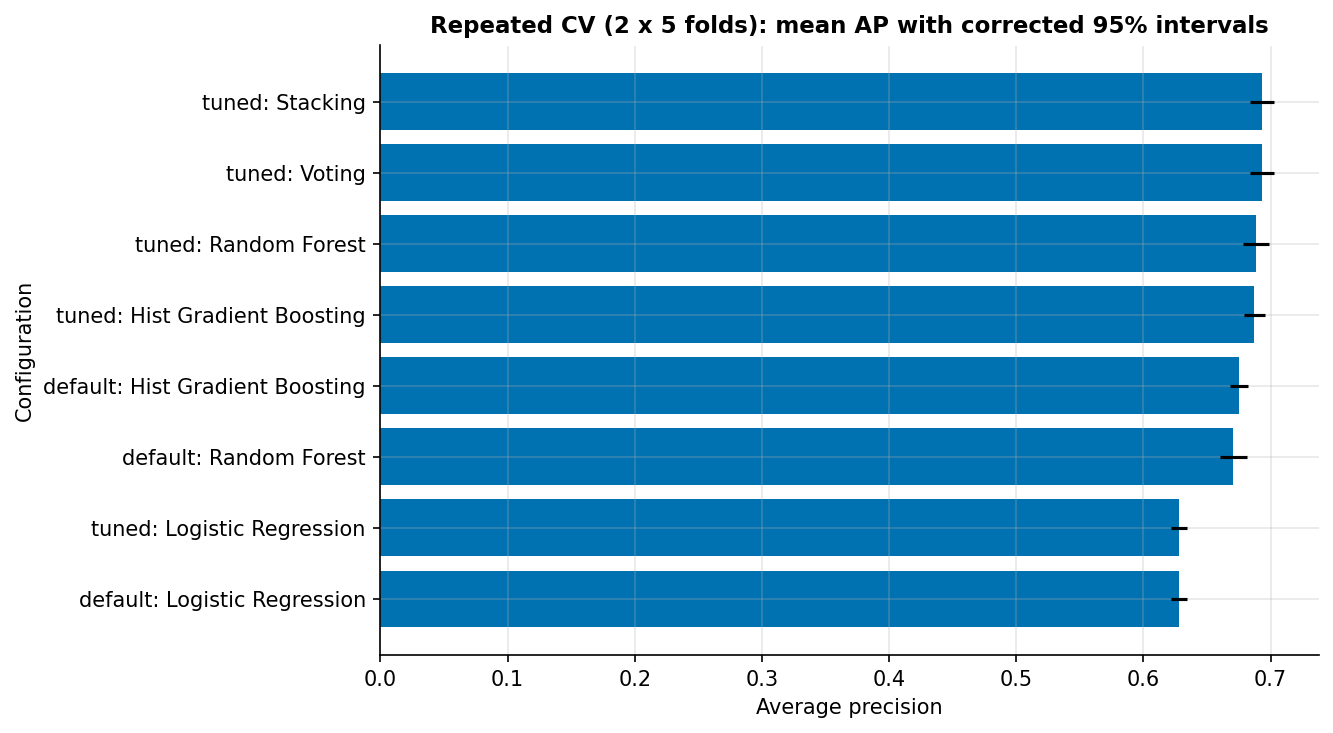

In [2]:
from src.robustness import repeated_uncertainty
summary, comparison = repeated_uncertainty()
display(summary)
display(comparison)
show('fig_D_02_repeated_uncertainty.png')